# Personalized cardio digital twin: prototype and validation

Pipeline: **population prior** (latest production bundle from `train_model.py`) →
**lab updates** (Kalman measurement step) → **wearable drift** (change against the user's own
30-day baseline, lagged by biomarker kinetics) → **AHA PREVENT** 10-year risk with uncertainty,
from the official AHA R package.

Every model call goes through `src/`, the same code the `/v1/twin/predict` endpoint runs.
Only the simulator lives in this notebook.

Two questions this notebook answers:
- **A. No labs, wearables only.** After 30 days, can we predict how biomarkers change?
- **B. Lab at signup, wearables only later.** Can we still predict the change?

In [1]:
import dataclasses
import warnings
from datetime import date, timedelta

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

from config.settings import settings
from src.components.model_artifact import QuantileModelBundle
from src.components.model_config import RANDOM_STATE, TARGETS, TEST_SIZE
from src.components.personalization.biomarker_config import BIOMARKERS
from src.components.personalization.distributions import forward
from src.components.personalization.kalman import effect_path
from src.components.prevent import PreventInputs, clip_to_validated, prevent_risk
from src.pipeline.prediction_pipeline import QuantilePredictor
from src.pipeline.training_pipeline import load_training_frame
from src.pipeline.twin_pipeline import TwinInputs, biomarker_samples, predict_twin

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.dpi"] = 110

bundle = QuantileModelBundle.load_latest(settings.model_dir)
prior = QuantilePredictor(bundle)
print("model version:", bundle.version)
pl.DataFrame(bundle.metrics["intervals"])

model version: 20261103T2116Z


target,interval,coverage,mean_width
str,str,f64,f64
"""non_hdl""","""80%""",0.772542,89.078204
"""hdl""","""80%""",0.762698,29.445069
"""hba1c""","""80%""",0.782147,1.125225
"""egfr""","""80%""",0.781444,35.801912
"""sbp""","""80%""",0.768436,32.607565


## Synthetic users

We start from NHANES participants aged 30–79 with every biomarker measured. Each person's
measured values are their **true day-0 levels**. They're drawn from a 20% split made with
the training seed. The production bundle refits on every labelled row, so the prior has seen
these people. That flatters the prior a little, which makes the twin's gains below
conservative. From there the simulator generates:
- a **true biomarker path**: day-0 level + lagged response to behaviour change + slow random
  drift. The true response uses the configured effect sizes × a per-user multiplier
  ~ N(1, 0.5), so the filter is **not** told the exact truth.
- **daily wearables** with day-to-day noise and about 10% missing days.
- **labs**: truth × (1 + measurement noise at the configured CV).

Behaviour change starts on day 45: more steps, a lower resting HR, and gradual weight loss.
The control scenario has no change.

In [2]:
PROFILE_COLS = [
    "sex",
    "age",
    "race_eth",
    "height_cm",
    "weight_kg",
    "waist_cm",
    "smoking",
    "told_high_bp",
    "bp_meds",
    "told_high_chol",
    "chol_meds",
    "diabetes_dx",
    "prediabetes_dx",
    "insulin",
    "diabetes_pills",
]
SIMULATED_FEATURES = ["steps", "resting_hr", "sleep_h", "weight_kg"]
START = date(2026, 1, 1)
N_DAYS = 180
CHANGE_DAY = 45
DAY_INDEX = np.arange(N_DAYS)
DATES = [START + timedelta(days=int(day)) for day in DAY_INDEX]

frame = load_training_frame(settings)
_, held_out_rows = train_test_split(
    np.arange(frame.height), test_size=TEST_SIZE, random_state=RANDOM_STATE
)
cohort = (
    frame[np.sort(held_out_rows)]
    .drop_nulls([*TARGETS, "height_cm", "weight_kg"])
    .filter(pl.col("age").is_between(30, 79))
)
print("cohort size:", cohort.height)


def to_profile(row: dict) -> dict:
    """Twin profile with integer NHANES codes from a cohort row."""
    profile = {column: row[column] for column in PROFILE_COLS}
    profile["sex"], profile["race_eth"] = int(row["sex"]), int(row["race_eth"])
    return profile


def simulate_wearables(row: dict, rng: np.random.Generator, change: bool):
    """Observed daily wearables (with gaps) and the true driver changes."""
    active = (DAY_INDEX >= CHANGE_DAY) & change
    step_gain = rng.uniform(1500, 5000) if change else 0.0
    resting_hr_drop = rng.uniform(0, 4) if change else 0.0
    weight_rate = rng.uniform(0.0, 0.05) if change else 0.0
    weight_drop = np.where(
        active, np.minimum(DAY_INDEX - CHANGE_DAY, 90) * weight_rate, 0.0
    )
    missing = pl.lit(pl.Series(rng.random(N_DAYS) < 0.10))
    observed = pl.DataFrame(
        {
            "date": DATES,
            "steps": rng.normal(6000, 1800)
            + active * step_gain
            + rng.normal(0, 1500, N_DAYS),
            "resting_hr": rng.normal(70, 6)
            - active * resting_hr_drop
            + rng.normal(0, 2, N_DAYS),
            "sleep_h": rng.normal(6.9, 0.7) + rng.normal(0, 0.6, N_DAYS),
            "weight_kg": row["weight_kg"] - weight_drop + rng.normal(0, 0.4, N_DAYS),
        }
    ).with_columns(
        pl.when(missing).then(None).otherwise(pl.col(name)).alias(name)
        for name in SIMULATED_FEATURES
    )
    true_deltas = pl.DataFrame(
        {
            "date": DATES,
            "steps": active * step_gain / 1000.0,
            "resting_hr": active * -resting_hr_drop,
            "sleep_h": np.zeros(N_DAYS),
            "weight_kg": -weight_drop,
        }
    )
    return observed.to_dicts(), true_deltas


def simulate_truth(
    row: dict, true_deltas: pl.DataFrame, rng: np.random.Generator
) -> dict:
    """True daily biomarker paths: day-0 level, lagged response, drift."""
    truth = {}
    for name, spec in BIOMARKERS.items():
        multiplier = max(rng.normal(1.0, 0.5), 0.0)
        true_spec = dataclasses.replace(
            spec,
            effects={key: value * multiplier for key, value in spec.effects.items()},
        )
        effect = effect_path(true_spec, true_deltas)
        drift = np.cumsum(rng.normal(0, spec.annual_drift_cv / np.sqrt(365), N_DAYS))
        drift[0] = 0.0
        truth[name] = np.clip((row[name] + effect) * (1 + drift), *spec.clamp)
    return truth


def draw_labs(truth: dict, lab_days: list[int], rng: np.random.Generator) -> list[dict]:
    """Noisy lab results drawn from the truth on the given days."""
    return [
        {
            "date": DATES[day],
            "biomarker": name,
            "value": float(truth[name][day] * (1 + rng.normal(0, spec.measurement_cv))),
        }
        for day in lab_days
        for name, spec in BIOMARKERS.items()
    ]


SCENARIOS = {
    "A: wearables only": {"labs": [], "change": True},
    "B: lab day 0 + wearables": {"labs": [0], "change": True},
    "C: labs day 0 & 120 + wearables": {"labs": [0, 120], "change": True},
    "D: lab day 0, no behaviour change": {"labs": [0], "change": False},
}

cohort size: 878


## One user, four scenarios

The same person runs through every scenario with `as_of` = day 120 and a 60-day forecast.
Shaded band: 80% interval. Dashed line: truth. Dots: labs.

{'sex': 1, 'age': 74.0, 'race_eth': 3, 'weight_kg': 72.6, 'smoking': 'former', 'bp_meds': 1, 'chol_meds': 1}


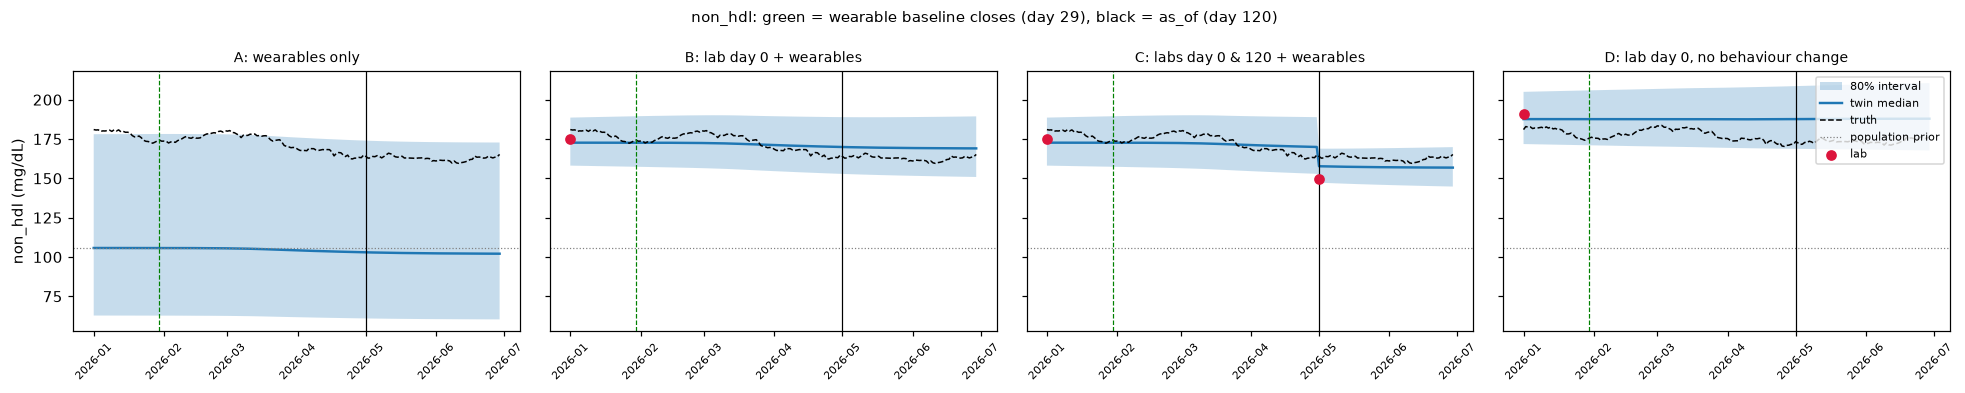

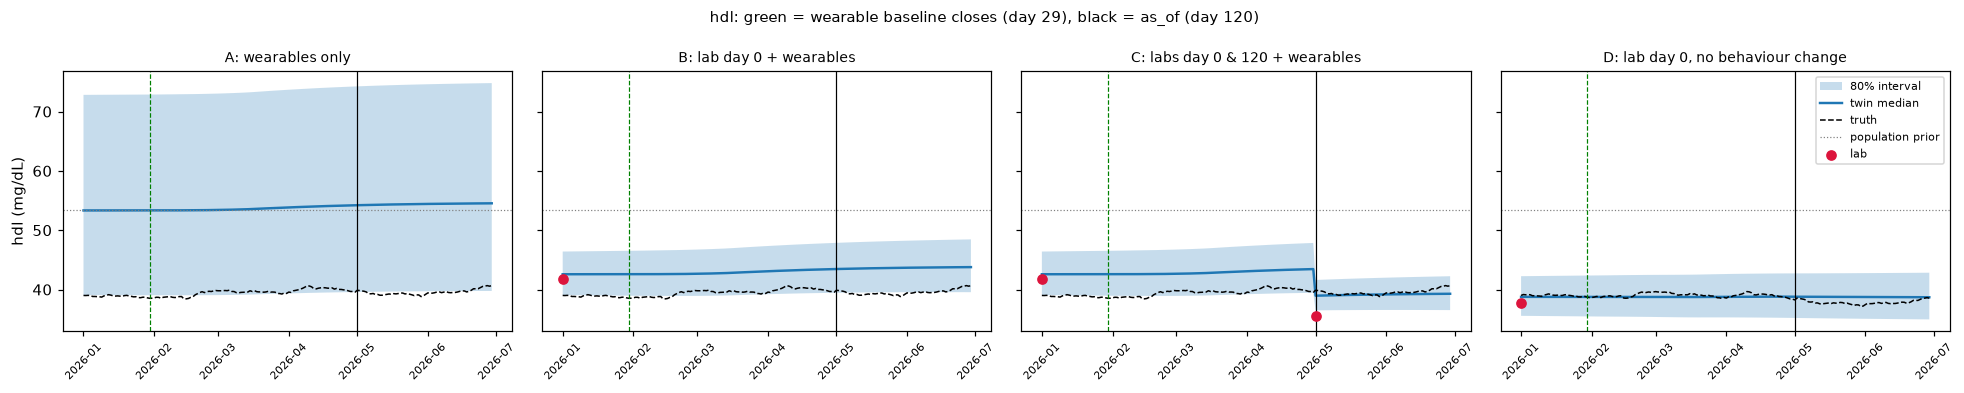

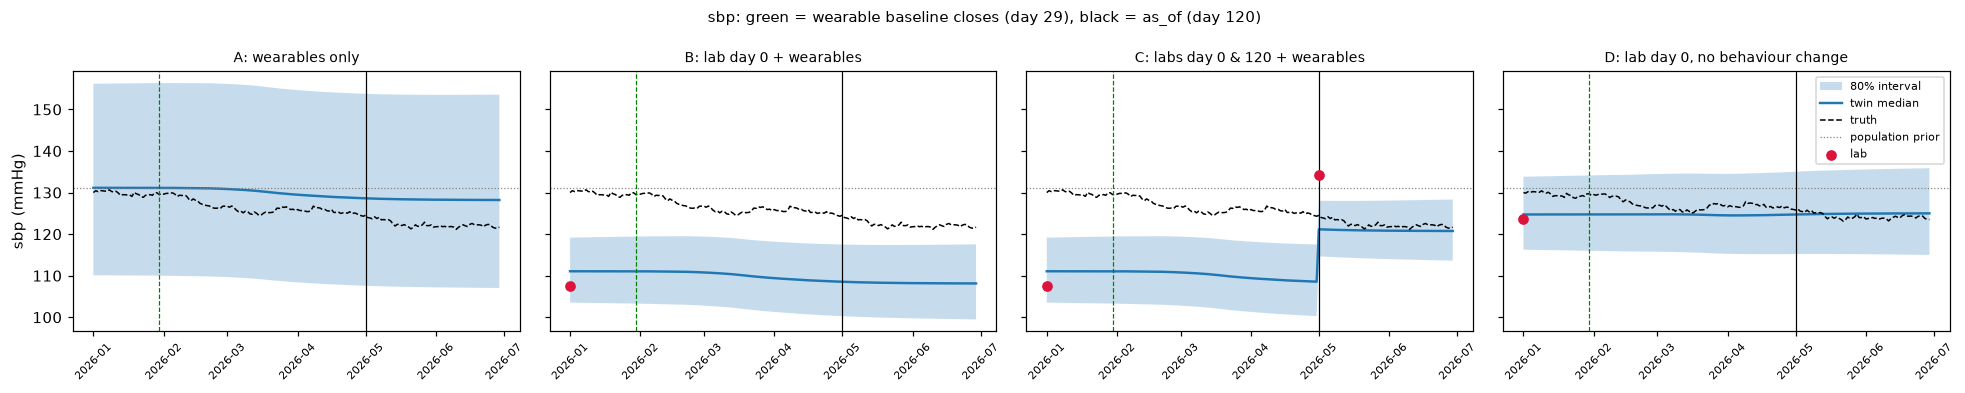

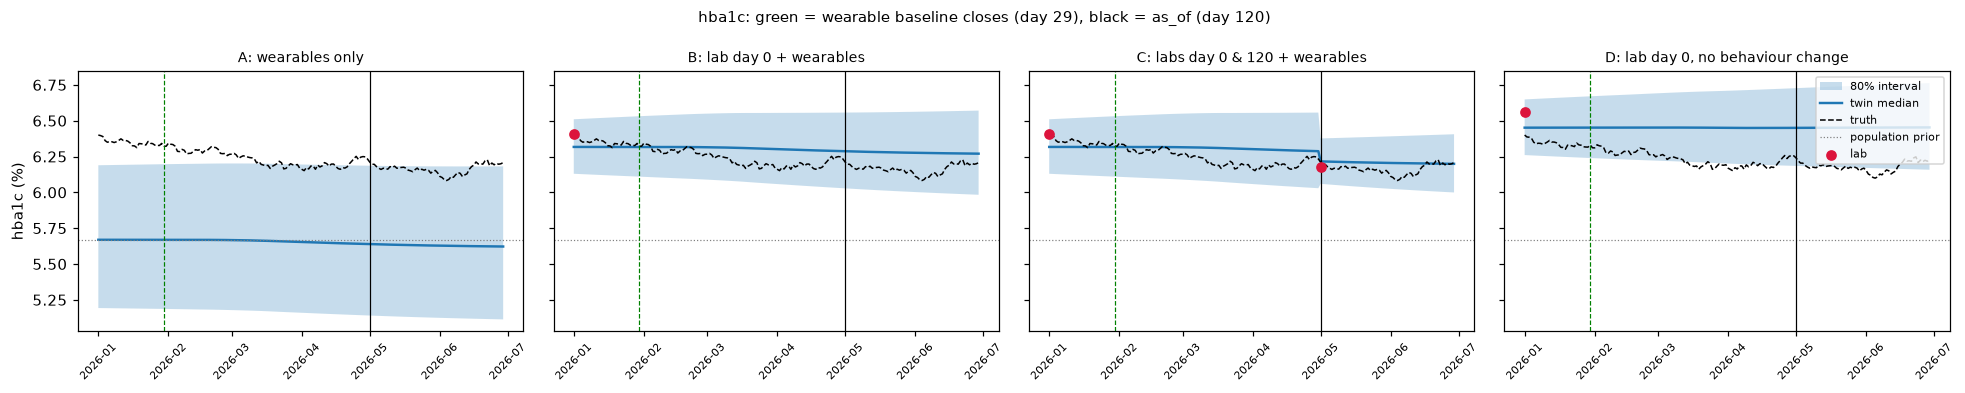

In [3]:
AS_OF_DAY = 120
AS_OF = DATES[AS_OF_DAY]

rng = np.random.default_rng(7)
showcase = cohort.row(int(rng.integers(cohort.height)), named=True)
profile = to_profile(showcase)
print(
    {
        key: profile[key]
        for key in (
            "sex",
            "age",
            "race_eth",
            "weight_kg",
            "smoking",
            "bp_meds",
            "chol_meds",
        )
    }
)

showcase_runs = {}
for label, config in SCENARIOS.items():
    scenario_rng = np.random.default_rng(11)
    wearables, true_deltas = simulate_wearables(
        showcase, scenario_rng, config["change"]
    )
    truth = simulate_truth(showcase, true_deltas, scenario_rng)
    labs = draw_labs(truth, config["labs"], scenario_rng)
    inputs = TwinInputs(
        profile=profile,
        labs=[lab for lab in labs if lab["date"] <= AS_OF],
        wearable_days=[day for day in wearables if day["date"] <= AS_OF],
        as_of=AS_OF,
        horizon_days=N_DAYS - 1 - AS_OF_DAY,
    )
    showcase_runs[label] = {
        "twin": predict_twin(prior, inputs),
        "truth": truth,
        "labs": labs,
        "wearables": wearables,
    }


def plot_trajectories(biomarker: str) -> None:
    """Fan chart of one biomarker across all scenarios."""
    fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(18, 3.6), sharey=True)
    for ax, (label, run) in zip(axes, showcase_runs.items(), strict=True):
        trajectory = run["twin"].biomarkers[biomarker].trajectory
        days = trajectory["date"].to_list()
        ax.fill_between(
            days, trajectory["q10"], trajectory["q90"], alpha=0.25, label="80% interval"
        )
        ax.plot(days, trajectory["q50"], lw=1.6, label="twin median")
        ax.plot(DATES, run["truth"][biomarker], "k--", lw=1, label="truth")
        ax.axhline(
            run["twin"].prior_quantiles[biomarker][0.5],
            color="grey",
            lw=0.8,
            ls=":",
            label="population prior",
        )
        lab_points = [
            (lab["date"], lab["value"])
            for lab in run["labs"]
            if lab["biomarker"] == biomarker
        ]
        if lab_points:
            lab_days, lab_values = zip(*lab_points, strict=True)
            ax.scatter(lab_days, lab_values, color="crimson", zorder=5, label="lab")
        ax.axvline(DATES[29], color="green", lw=0.8, ls="--")
        ax.axvline(AS_OF, color="black", lw=0.8)
        ax.set_title(label, fontsize=9)
        ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    axes[0].set_ylabel(f"{biomarker} ({BIOMARKERS[biomarker].unit})")
    axes[-1].legend(fontsize=7, loc="upper right")
    fig.suptitle(
        f"{biomarker}: green = wearable baseline closes (day 29), "
        "black = as_of (day 120)",
        fontsize=10,
    )
    fig.tight_layout()
    plt.show()


for biomarker in ("non_hdl", "hdl", "sbp", "hba1c"):
    plot_trajectories(biomarker)

### Prior vs posterior and uncertainty over time

The left panel compares the prior density with the posterior on `as_of` for scenario B. The
right panel shows posterior SD relative to the prior SD. It collapses at each lab, then
slowly grows back as time passes.

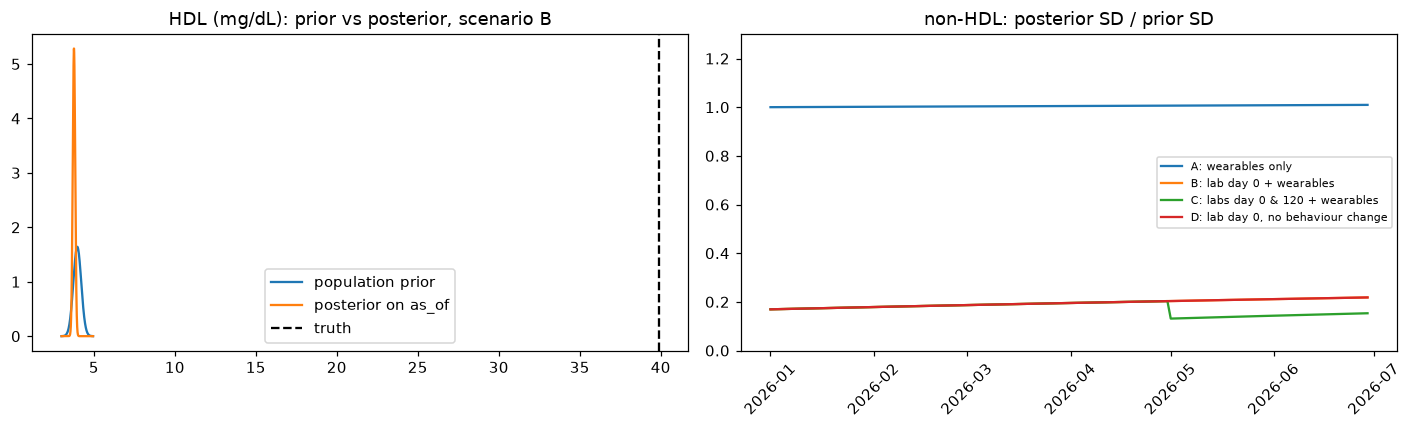

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
run_b = showcase_runs["B: lab day 0 + wearables"]
hdl_result = run_b["twin"].biomarkers["hdl"]
as_of_row = hdl_result.trajectory.filter(pl.col("date") == AS_OF).row(0, named=True)
grid = np.linspace(
    hdl_result.prior.mean - 4 * hdl_result.prior.sd,
    hdl_result.prior.mean + 4 * hdl_result.prior.sd,
    400,
)
axes[0].plot(
    grid,
    norm.pdf(grid, hdl_result.prior.mean, hdl_result.prior.sd),
    label="population prior",
)
axes[0].plot(
    grid, norm.pdf(grid, as_of_row["mean"], as_of_row["sd"]), label="posterior on as_of"
)
axes[0].axvline(run_b["truth"]["hdl"][AS_OF_DAY], color="k", ls="--", label="truth")
axes[0].set_title("HDL (mg/dL): prior vs posterior, scenario B")
axes[0].legend()

for label, run in showcase_runs.items():
    result = run["twin"].biomarkers["non_hdl"]
    axes[1].plot(
        result.trajectory["date"].to_list(),
        result.trajectory["sd"] / result.prior.sd,
        label=label,
    )
axes[1].set_title("non-HDL: posterior SD / prior SD")
axes[1].set_ylim(0, 1.3)
axes[1].legend(fontsize=7)
axes[1].tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

### Wearable change against the user's own baseline

Trailing 30-day means for scenario A. The baseline window is days 0–29. The change starts on
day 45.

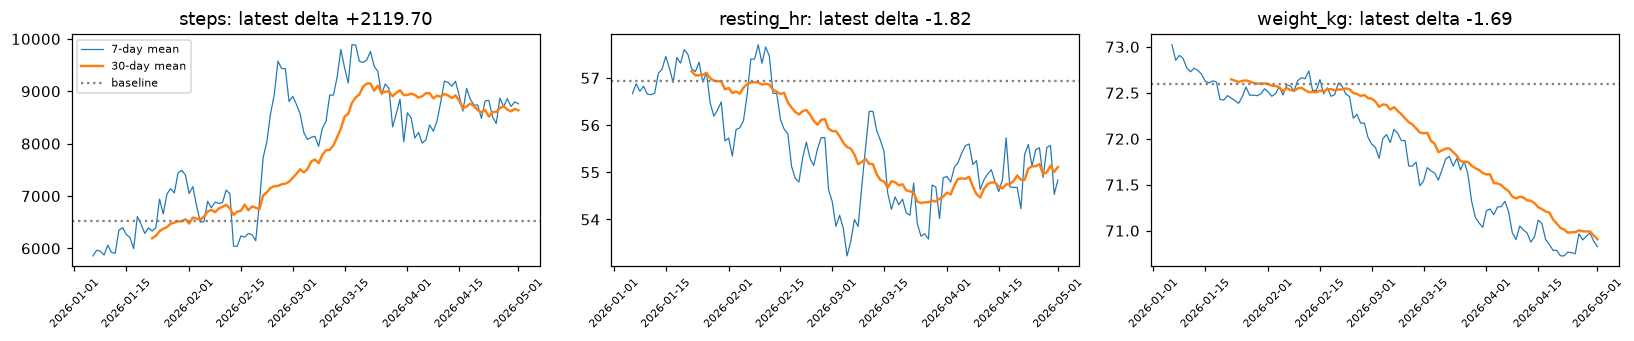

In [5]:
wearable_a = showcase_runs["A: wearables only"]["twin"].wearable
rolling_days = wearable_a.rolling["date"].to_list()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, feature in zip(axes, ("steps", "resting_hr", "weight_kg"), strict=True):
    ax.plot(
        rolling_days, wearable_a.rolling[f"{feature}_7d"], lw=0.8, label="7-day mean"
    )
    ax.plot(
        rolling_days, wearable_a.rolling[f"{feature}_30d"], lw=1.6, label="30-day mean"
    )
    if wearable_a.baseline.get(feature) is not None:
        ax.axhline(wearable_a.baseline[feature], color="grey", ls=":", label="baseline")
    ax.set_title(f"{feature}: latest delta {wearable_a.latest_delta[feature]:+.2f}")
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

### PREVENT 10-year risk: population prior vs personalized

Monte-Carlo samples from each biomarker distribution go through the official AHA PREVENT R
package (`AHAprevent::prevent_base`, v1.1.0), called through rpy2. "True" risk is the same
package applied to the simulated true biomarkers on `as_of`.

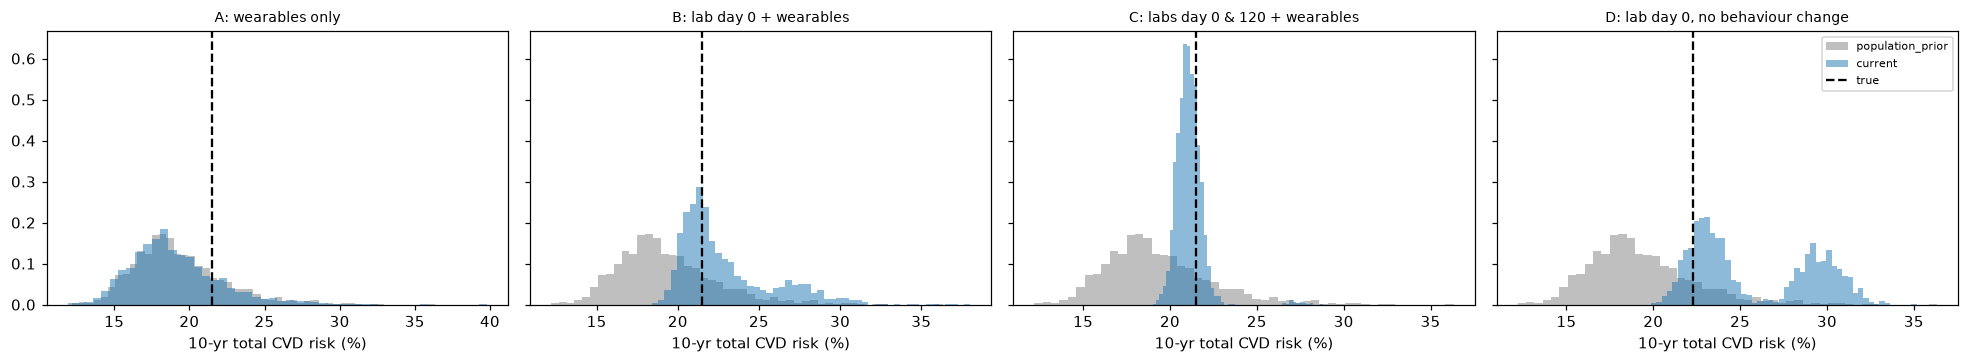

view,outcome,A: wearables only,B: lab day 0 + wearables,C: labs day 0 & 120 + wearables,"D: lab day 0, no behaviour change"
str,str,f64,f64,f64,f64
"""population_prior""","""total_cvd""",18.75,18.75,18.75,18.75
"""population_prior""","""ascvd""",10.28,10.28,10.28,10.28
"""population_prior""","""heart_failure""",12.73,12.73,12.73,12.73
"""current""","""total_cvd""",18.54,22.26,21.02,24.46
"""current""","""ascvd""",10.07,13.94,13.15,17.32
"""current""","""heart_failure""",12.75,13.29,12.07,12.62
"""forecast""","""total_cvd""",18.47,22.4,20.93,24.8
"""forecast""","""ascvd""",10.02,13.97,13.07,17.6
"""forecast""","""heart_failure""",12.74,13.5,12.07,12.73


In [6]:
def recent_weight(wearables: list[dict], until: date) -> float:
    """Mean of the last 30 observed weights up to a day."""
    weights = [
        day["weight_kg"]
        for day in wearables
        if day["date"] <= until and day["weight_kg"] is not None
    ]
    return float(np.mean(weights[-30:]))


def risk_inputs(row: dict, biomarkers: dict, weight: float) -> PreventInputs:
    """PREVENT inputs from a cohort row and biomarker values or samples."""
    diabetes = (row["diabetes_dx"] == "yes") | (np.asarray(biomarkers["hba1c"]) >= 6.5)
    return PreventInputs(
        age=float(row["age"]),
        sex=int(row["sex"]),
        total_chol=clip_to_validated(
            "total_chol", np.asarray(biomarkers["non_hdl"]) + biomarkers["hdl"]
        ),
        hdl=clip_to_validated("hdl", biomarkers["hdl"]),
        sbp=clip_to_validated("sbp", biomarkers["sbp"]),
        bmi=clip_to_validated("bmi", weight / (row["height_cm"] / 100) ** 2),
        egfr=biomarkers["egfr"],
        diabetes=np.asarray(diabetes, dtype=float),
        smoking=float(row["smoking"] == "current"),
        bp_treated=float(row["bp_meds"] == 1),
        statin=float(row["chol_meds"] == 1),
    )


def true_total_cvd(row: dict, truth: dict, day: int, weight: float) -> float:
    """PREVENT total CVD risk on the simulated true biomarkers."""
    true_values = {name: truth[name][day] for name in truth}
    return float(prevent_risk(risk_inputs(row, true_values, weight))["total_cvd"][0])


fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(18, 3.4), sharey=True)
for ax, (label, run) in zip(axes, showcase_runs.items(), strict=True):
    twin = run["twin"]
    if not twin.prevent:
        ax.set_title(f"{label}\n{twin.prevent_note}", fontsize=8)
        continue
    weight = recent_weight(run["wearables"], AS_OF)
    for view, color in (("population_prior", "grey"), ("current", "tab:blue")):
        samples = biomarker_samples(
            twin, None if view == "population_prior" else AS_OF, 2000, 0
        )
        risk = prevent_risk(risk_inputs(showcase, samples, weight))["total_cvd"]
        ax.hist(risk * 100, bins=50, alpha=0.5, color=color, label=view, density=True)
    ax.axvline(
        true_total_cvd(showcase, run["truth"], AS_OF_DAY, weight) * 100,
        color="k",
        ls="--",
        label="true",
    )
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("10-yr total CVD risk (%)")
axes[-1].legend(fontsize=7)
fig.tight_layout()
plt.show()

pl.DataFrame(
    [
        {
            "scenario": label,
            "view": view,
            "outcome": outcome,
            "median_%": round(values["median"] * 100, 2),
        }
        for label, run in showcase_runs.items()
        for view, outcomes in run["twin"].prevent.items()
        for outcome, values in outcomes.items()
    ]
).pivot(on="scenario", index=["view", "outcome"], values="median_%")

## Validation across the cohort

For every user and scenario, filter through day 179 and score against the truth on day 90
and day 179:
- **coverage**: share of truths inside the 80% interval (target 0.80)
- **MAE**: twin median vs truth, compared with the population-prior median vs truth
- **CRPS** (Gaussian, working scale): accuracy and calibration in one number; lower is better
- **innovation z** at the second lab in scenario C: should look like N(0, 1)
- **PREVENT error**: |predicted median − true risk| for prior vs twin

In [7]:
N_USERS = min(300, cohort.height)
EVAL_DAYS = (90, 179)
END = DATES[-1]


def gaussian_crps(mu: float, sigma: float, observed: float) -> float:
    """CRPS of a normal forecast against one observation."""
    z = (observed - mu) / sigma
    return float(
        sigma * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))
    )


rows, innovations, risk_rows = [], [], []
seeds = np.random.default_rng(2026).integers(1_000_000_000, size=N_USERS)
for person, seed in tqdm(
    zip(cohort.head(N_USERS).iter_rows(named=True), seeds, strict=True),
    total=N_USERS,
    desc="Simulating users through the twin and PREVENT",
):
    person_profile = to_profile(person)
    for label, config in SCENARIOS.items():
        scenario_rng = np.random.default_rng(seed)
        wearables, true_deltas = simulate_wearables(
            person, scenario_rng, config["change"]
        )
        truth = simulate_truth(person, true_deltas, scenario_rng)
        labs = draw_labs(truth, config["labs"], scenario_rng)
        twin = predict_twin(
            prior,
            TwinInputs(
                profile=person_profile,
                labs=labs,
                wearable_days=wearables,
                as_of=END,
                horizon_days=0,
            ),
        )
        for name, result in twin.biomarkers.items():
            transform = BIOMARKERS[name].transform
            for day in EVAL_DAYS:
                point = result.trajectory.row(day, named=True)
                observed = truth[name][day]
                rows.append(
                    {
                        "scenario": label,
                        "biomarker": name,
                        "day": day,
                        "covered": point["q10"] <= observed <= point["q90"],
                        "abs_err_twin": abs(point["q50"] - observed),
                        "abs_err_prior": abs(
                            twin.prior_quantiles[name][0.5] - observed
                        ),
                        "crps_twin": gaussian_crps(
                            point["mean"],
                            point["sd"],
                            float(forward(observed, transform)),
                        ),
                        "crps_prior": gaussian_crps(
                            result.prior.mean,
                            result.prior.sd,
                            float(forward(observed, transform)),
                        ),
                    }
                )
            if label.startswith("C") and len(result.innovations) == 2:
                innovations.append({"biomarker": name, "z": result.innovations[1].z})
        if twin.prevent:
            true_value = true_total_cvd(
                person, truth, N_DAYS - 1, recent_weight(wearables, END)
            )
            risk_rows.append(
                {
                    "scenario": label,
                    "err_prior": abs(
                        twin.prevent["population_prior"]["total_cvd"]["median"]
                        - true_value
                    ),
                    "err_twin": abs(
                        twin.prevent["current"]["total_cvd"]["median"] - true_value
                    ),
                }
            )

summary = (
    pl.DataFrame(rows)
    .group_by(["scenario", "biomarker", "day"])
    .agg(
        pl.col("covered").mean().alias("coverage_80"),
        pl.col("abs_err_prior").mean().alias("mae_prior"),
        pl.col("abs_err_twin").mean().alias("mae_twin"),
        pl.col("crps_prior").mean(),
        pl.col("crps_twin").mean(),
    )
    .with_columns(
        (100 * (1 - pl.col("mae_twin") / pl.col("mae_prior"))).alias("mae_reduction_%")
    )
    .sort(["scenario", "biomarker", "day"])
)
summary.with_columns(pl.selectors.float().round(3))

Simulating users through the twin and PREVENT:   0%|          | 0/300 [00:00<?, ?it/s]

scenario,biomarker,day,coverage_80,mae_prior,mae_twin,crps_prior,crps_twin,mae_reduction_%
str,str,i64,f64,f64,f64,f64,f64,f64
"""A: wearables only""","""egfr""",90,0.86,10.586,10.586,0.089,0.089,-0.0
"""A: wearables only""","""egfr""",179,0.857,10.584,10.584,0.089,0.089,-0.0
"""A: wearables only""","""hba1c""",90,0.813,0.417,0.417,0.049,0.049,0.016
"""A: wearables only""","""hba1c""",179,0.793,0.446,0.442,0.053,0.052,0.873
"""A: wearables only""","""hdl""",90,0.837,9.175,9.155,0.119,0.119,0.219
…,…,…,…,…,…,…,…,…
"""D: lab day 0, no behaviour cha…","""hdl""",179,0.817,9.231,3.359,0.121,0.045,63.609
"""D: lab day 0, no behaviour cha…","""non_hdl""",90,0.797,23.256,8.2,0.134,0.044,64.739
"""D: lab day 0, no behaviour cha…","""non_hdl""",179,0.79,24.038,9.405,0.137,0.05,60.875


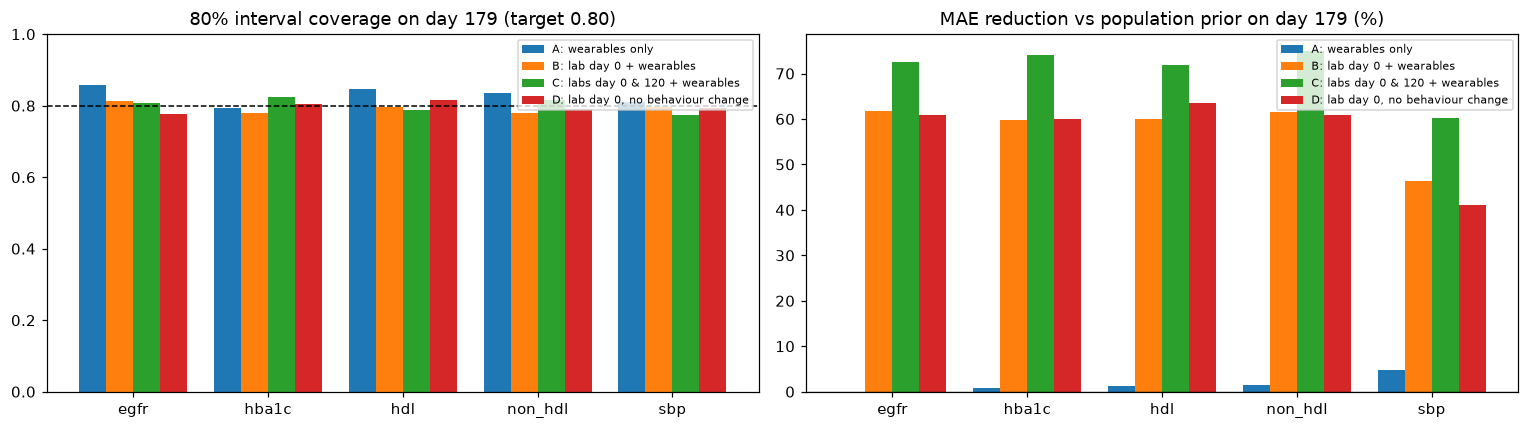

In [8]:
def grouped_bars(ax, metric: str, title: str) -> None:
    """Bar chart of a day-179 metric per biomarker and scenario."""
    final_day = summary.filter(pl.col("day") == 179)
    biomarkers = sorted(final_day["biomarker"].unique().to_list())
    positions = np.arange(len(biomarkers))
    width = 0.8 / len(SCENARIOS)
    for offset, label in enumerate(SCENARIOS):
        values = final_day.filter(pl.col("scenario") == label).sort("biomarker")[metric]
        ax.bar(positions + offset * width, values, width, label=label)
    ax.set_xticks(positions + width * (len(SCENARIOS) - 1) / 2, biomarkers)
    ax.set_title(title)
    ax.legend(fontsize=7)


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
grouped_bars(axes[0], "coverage_80", "80% interval coverage on day 179 (target 0.80)")
axes[0].axhline(0.8, color="k", ls="--", lw=1)
axes[0].set_ylim(0, 1)
grouped_bars(
    axes[1], "mae_reduction_%", "MAE reduction vs population prior on day 179 (%)"
)
axes[1].axhline(0, color="k", lw=0.8)
fig.tight_layout()
plt.show()

shape: (5, 4)
┌───────────┬───────┬──────┬───────┐
│ biomarker ┆ mean  ┆ std  ┆ count │
│ ---       ┆ ---   ┆ ---  ┆ ---   │
│ str       ┆ f64   ┆ f64  ┆ u32   │
╞═══════════╪═══════╪══════╪═══════╡
│ egfr      ┆ -0.08 ┆ 1.08 ┆ 300   │
│ hba1c     ┆ 0.02  ┆ 1.05 ┆ 300   │
│ hdl       ┆ 0.08  ┆ 0.99 ┆ 300   │
│ non_hdl   ┆ -0.02 ┆ 1.06 ┆ 300   │
│ sbp       ┆ -0.1  ┆ 0.98 ┆ 300   │
└───────────┴───────┴──────┴───────┘


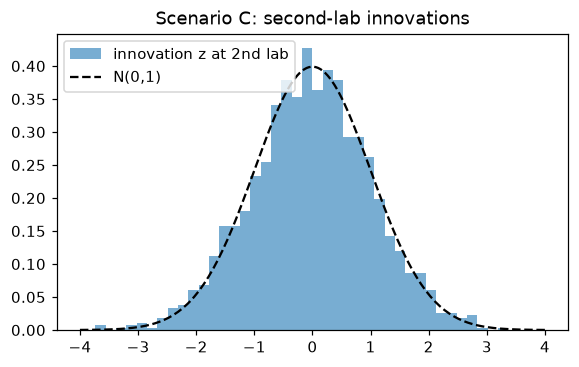

scenario,MAE prior (pct-pts),MAE twin (pct-pts)
str,f64,f64
"""A: wearables only""",1.327,1.289
"""B: lab day 0 + wearables""",1.327,0.603
"""C: labs day 0 & 120 + wearable…",1.327,0.475
"""D: lab day 0, no behaviour cha…",1.384,0.742


In [9]:
innovation_frame = pl.DataFrame(innovations)
print(
    innovation_frame.group_by("biomarker")
    .agg(
        pl.col("z").mean().alias("mean"),
        pl.col("z").std().alias("std"),
        pl.len().alias("count"),
    )
    .sort("biomarker")
    .with_columns(pl.col("mean", "std").round(2))
)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(
    innovation_frame["z"],
    bins=40,
    density=True,
    alpha=0.6,
    label="innovation z at 2nd lab",
)
grid = np.linspace(-4, 4, 200)
ax.plot(grid, norm.pdf(grid), "k--", label="N(0,1)")
ax.legend()
ax.set_title("Scenario C: second-lab innovations")
plt.show()

(
    pl.DataFrame(risk_rows)
    .group_by("scenario")
    .agg(
        (pl.col("err_prior").mean() * 100).round(3).alias("MAE prior (pct-pts)"),
        (pl.col("err_twin").mean() * 100).round(3).alias("MAE twin (pct-pts)"),
    )
    .sort("scenario")
)

## Reading the results and limits

- **Scenario A (wearables only).** The level stays anchored to the population prior, so the
  absolute error barely moves. What the twin adds is the *direction and size of change*,
  which starts after the 30-day baseline closes. Intervals stay wide, flagged
  `basis="estimated"` and `confidence="low"`.
- **Scenario B (lab at signup, wearables later).** The day-0 lab anchors the level. The
  wearable change measured after day 30 then moves the estimate. This is the case where
  personalization pays off most.
- **Scenario C.** The second lab re-anchors the level. Its innovation z-scores show whether
  the effect sizes and process noise are calibrated. Mean ≠ 0 means biased effects. SD > 1
  means overconfidence.
- **Limits.** Wearable effect sizes come from the literature (`biomarker_config.py`) and are
  not learned. This validation is on *simulated* users, so it checks that the machinery is
  self-consistent and calibrated when its assumptions roughly hold, not that real biology
  matches. Real validation needs paired data: labs at two or more time points plus wearables
  in between. Once that exists, fit per-user effect sizes with Bayesian linear regression,
  shrunk toward the literature values.